<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 3 — Derivatives and Integrals from Samples</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### Finite differences and the truncation/round-off trade-off, the CO₂ growth rate, the trapezoidal and Simpson's rules, and why grids fail in many dimensions.
***

## Where this fits

Interpolation builds a curve from samples. The same idea gives derivatives and integrals: if you only have $f$ at discrete points (or can only evaluate it), you estimate slopes and areas from those points.

Two threads from Week 1 come back:

- **round-off:** a finite difference subtracts two nearly equal numbers, the catastrophic cancellation from `week1_foundations.ipynb`;
- **RK4:** for $dy/dt = f(t)$, an RK4 step *is* Simpson's rule.

Lecture 4 covers the methods. Today you will:

1. write forward and central differences, find the step size that minimises the error, and improve on it with Richardson extrapolation;
2. differentiate the CO₂ record to get its growth rate;
3. see how differentiating measured values amplifies their noise, and how to fight it;
4. write the trapezoidal and Simpson's rules and measure how fast they converge;
5. use them on a real physics integral (the large-amplitude pendulum), where the "better" rule loses.

**Nothing here is assessed.** Write your predictions in your logbook before you run each comparison.

## How to use this notebook today

**Core (about 1¼ hours):** Sections 1, 2, 3, 4 and 6(a). Parts marked *Optional* (the second derivative, Sections 5 and 7, 6(b) and the extensions) can wait.

**Working on Exercise 1?** Sections 1, 3 and 4 give you the tools for Tasks 4 and 5: central differences, the noise they pick up, and Simpson's rule. Section 6 is the same elliptic integral as Task 4.3. Do those, then use the rest of the lab for the exercise.

**Behind on earlier weeks?** Catch up first on what Exercise 1 builds on: `week1_euler_rk4_lab.ipynb` (Sections 1–3 and 5), `week2_root_finding.ipynb` (Sections 1, 2 and 5), `week2_fitting.ipynb` (Sections 2–4) and `week2_code_and_plots.ipynb` (Section 6). This notebook will still be here.

In [1]:
import os

# Data: read from a local datasets/ folder if you've cloned/downloaded the
# repository, otherwise straight from GitHub (e.g. in Colab). Same file either way.
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/workshops/week3/datasets/"

def data_path(filename):
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## <span style="color:#B5121B">1. Finite differences</span>

From the Taylor series, $f(x + h) = f(x) + h f'(x) + \tfrac{h^2}{2} f''(x) + \tfrac{h^3}{6} f'''(x) + \dots$, so

$$\text{forward:}\quad f'(x) \approx \frac{f(x + h) - f(x)}{h}, \qquad \text{error} \approx \tfrac{h}{2} f''(x),$$

$$\text{central:}\quad f'(x) \approx \frac{f(x + h) - f(x - h)}{2h}, \qquad \text{error} \approx \tfrac{h^2}{6} f'''(x).$$

This is the *truncation* error: it shrinks as $h \to 0$. But the numerator subtracts two nearly equal numbers, each with a relative round-off error of about $\epsilon \approx 2\times10^{-16}$ (Week 1). That gives a *round-off* error of about $\epsilon |f| / h$, which grows as $h \to 0$.

**(a)** Write `forward_diff(f, x, h)` and `central_diff(f, x, h)`.

In [3]:
def forward_diff(f, x, h):
    """Forward-difference estimate of f'(x)."""
    return (f(x + h) - f(x)) / h

def central_diff(f, x, h):
    """Central-difference estimate of f'(x)."""
    return (f(x + h) - f(x - h)) / (2 * h)

In [4]:
try:
    print(forward_diff(np.sin, 1.0, 1e-3), central_diff(np.sin, 1.0, 1e-3), "exact", np.cos(1.0))
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

0.5398814803603269 0.5403022158176896 exact 0.5403023058681398


**(b)** **Predict first**, in your logbook: what value of $h$ gives the most accurate derivative? Is smaller always better?

For $f(x) = \sin x$ at $x = 1$, compute the absolute error of both methods for $h$ from $10^{-16}$ to $1$ (`np.logspace(-16, 0, 161)`). Plot both on log–log axes. Add the lines $h/2$ and $h^2/6$ (truncation) and $\epsilon/h$ (round-off) for comparison.

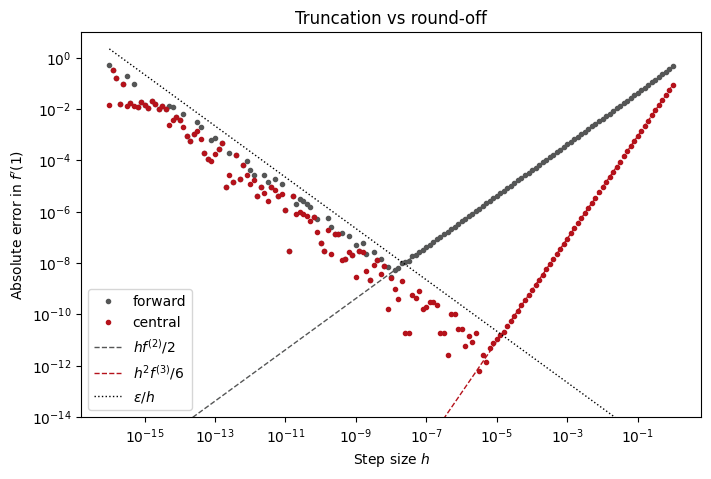

forward: best h = 3e-09, error = 2e-09
central: best h = 3e-06, error = 6e-13
sqrt(eps) = 1e-08, eps^(1/3) = 6e-06


In [5]:
hs = np.logspace(-16, 0, 161)
eps = np.finfo(float).eps
x0, exact = 1.0, np.cos(1.0)

err_fw = np.abs(forward_diff(np.sin, x0, hs) - exact)
err_ce = np.abs(central_diff(np.sin, x0, hs) - exact)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs, err_fw, ".", color="#555656", label="forward")
ax.loglog(hs, err_ce, ".", color="#B5121B", label="central")
ax.loglog(hs, hs / 2 * np.sin(1.0), "--", color="#555656", lw=1, label="$h f^{(2)}/2$")
ax.loglog(hs, hs**2 / 6 * np.cos(1.0), "--", color="#B5121B", lw=1, label="$h^2 f^{(3)}/6$")
ax.loglog(hs, eps / hs, ":", color="k", lw=1, label="$\\epsilon / h$")
ax.set_ylim(1e-14, 10)
ax.set_xlabel("Step size $h$")
ax.set_ylabel("Absolute error in $f'(1)$")
ax.set_title("Truncation vs round-off")
ax.legend()
plt.show()

for name, err in [("forward", err_fw), ("central", err_ce)]:
    print(f"{name}: best h = {hs[np.argmin(err)]:.0e}, error = {err.min():.0e}")
print(f"sqrt(eps) = {np.sqrt(eps):.0e}, eps^(1/3) = {eps**(1/3):.0e}")

<span style="color:#38614A">**Answer.**</span> A U-shaped curve. To the right, truncation error falls as $h$ (forward, slope 1) or $h^2$ (central, slope 2). To the left, round-off grows as $\epsilon/h$, and the points scatter because the round-off is effectively random. The best forward step is around $10^{-8}$ to $10^{-9}$ (error $\sim 10^{-9}$); the best central step is a few times $10^{-6}$ (error below $10^{-12}$). These match balancing the two errors: $h \sim \sqrt{\epsilon}$ for forward and $h \sim \epsilon^{1/3}$ for central. Smaller is *not* always better; below $h \approx 10^{-15}$ the numerator is pure round-off. This is the Week 1 catastrophic cancellation again.

In your logbook: the best possible accuracy of each method, and the step size that achieves it. Why does central win twice over (better accuracy *and* a larger, safer step)?

**(c) Richardson extrapolation.** Lecture 4 showed that if the error is $Ch^p$ with known $p$, two estimates $A(h)$ and $A(h/2)$ combine to cancel the leading term:

$$A \approx \frac{2^p A(h/2) - A(h)}{2^p - 1}.$$

For the central difference $p = 2$. At $x = 1$, compute the central difference and the Richardson estimate for $h = 0.1$, $0.01$ and $0.001$. How do the errors compare with the best plain central difference from (b)?

In [6]:
for h in [0.1, 0.01, 0.001]:
    A_h, A_h2 = central_diff(np.sin, 1.0, h), central_diff(np.sin, 1.0, h / 2)
    richardson = (4 * A_h2 - A_h) / 3
    print(f"h = {h:<6}: central error {abs(A_h - np.cos(1.0)):.1e}, Richardson error {abs(richardson - np.cos(1.0)):.1e}")

h = 0.1   : central error 9.0e-04, Richardson error 1.1e-07
h = 0.01  : central error 9.0e-06, Richardson error 1.1e-11
h = 0.001 : central error 9.0e-08, Richardson error 3.5e-14


<span style="color:#38614A">**Answer.**</span> At $h = 0.1$ the error drops from $9\times10^{-4}$ to $1\times10^{-7}$ (the lecture's numbers); at $h = 0.01$, from $9\times10^{-6}$ to $1\times10^{-11}$. At $h = 0.001$ Richardson reaches $\sim3\times10^{-14}$, better than the best plain central difference ($6\times10^{-13}$, which needs $h$ near $10^{-6}$, close to the round-off region). Extrapolating *in $h$* is safe because we know the form of the error, and it gets high accuracy from a large, round-off-safe step.

## <span style="color:#FD9029">Optional: the second derivative</span>

$f''(x) \approx [f(x+h) - 2f(x) + f(x-h)]/h^2$, with truncation error $\tfrac{h^2}{12}f^{(4)}(x)$. Repeat (b) for $f''(1)$ of $\sin x$ (exact: $-\sin 1$). Where is the best $h$ now, and why has it moved?

best h = 2e-04, error = 2e-09


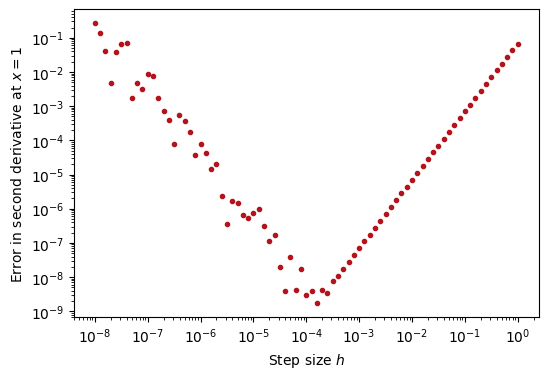

In [7]:
hs2 = np.logspace(-8, 0, 81)
d2 = (np.sin(1 + hs2) - 2 * np.sin(1) + np.sin(1 - hs2)) / hs2**2
err_d2 = np.abs(d2 + np.sin(1.0))
print(f"best h = {hs2[np.argmin(err_d2)]:.0e}, error = {err_d2.min():.0e}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(hs2, err_d2, ".", color="#B5121B")
ax.set_xlabel("Step size $h$")
ax.set_ylabel("Error in second derivative at $x = 1$")
plt.show()

<span style="color:#38614A">**Answer.**</span> Best $h \approx 2\times10^{-4}$, with error $\sim10^{-9}$. Round-off now grows as $\epsilon/h^2$ (we divide by $h^2$), so it takes over at a larger $h$: balancing $h^2$ against $\epsilon/h^2$ gives $h \sim \epsilon^{1/4} \approx 10^{-4}$. Each higher derivative taken by differencing is less accurate than the last.

## <span style="color:#B5121B">2. Differentiating real data: how fast is CO₂ rising?</span>

With data you can't choose $h$: it's the sampling interval (one month here), and the noise is far larger than round-off.

**(a)** Load the CO₂ record (as in `week3_interpolation.ipynb`) and estimate $dy/dt$ in ppm per year with `np.gradient(y, t)`, which uses central differences (and handles uneven spacing). Plot it. Is it the growth rate you were hoping to see?

In [8]:
co2 = pd.read_csv(data_path("co2_mm_mlo.csv"), comment="#")
t = co2["decimal date"].to_numpy()
y = co2["average"].to_numpy()

monthly central difference: -28 to 21 ppm/yr


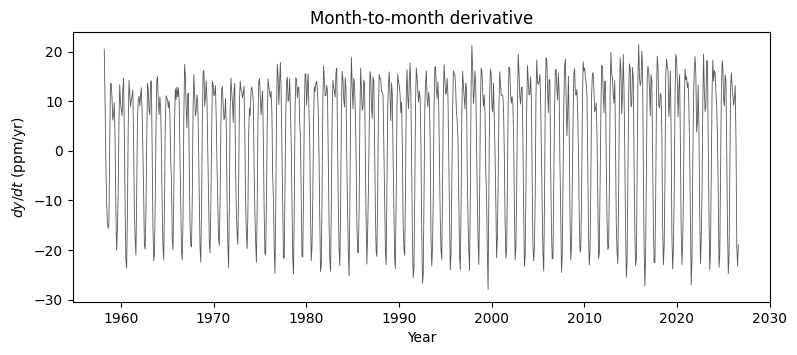

In [9]:
rate = np.gradient(y, t)
print(f"monthly central difference: {rate.min():.0f} to {rate.max():.0f} ppm/yr")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t, rate, lw=0.6, color="#555656")
ax.set_xlabel("Year")
ax.set_ylabel("$dy/dt$ (ppm/yr)")
ax.set_title("Month-to-month derivative")
plt.show()

<span style="color:#38614A">**Answer.**</span> The derivative swings between about −28 and +21 ppm/yr: it's dominated by the seasonal cycle (CO₂ falls each northern summer as plants grow), which is a real signal, but not the long-term growth rate we want. Differentiating amplifies the fast variations, because a sinusoid of frequency $\omega$ has derivative amplitude multiplied by $\omega$.

**(b)** A 12-month central difference, $[y(t + 6\,\text{mo}) - y(t - 6\,\text{mo})]$ per year, compares the same point of the seasonal cycle on both sides, so the cycle cancels. Compute it (`(y[12:] - y[:-12]) / (t[12:] - t[:-12])`, centred at `(t[12:] + t[:-12]) / 2`). Plot it and print the mean growth rate for each decade. What has happened to the growth rate since the 1960s?

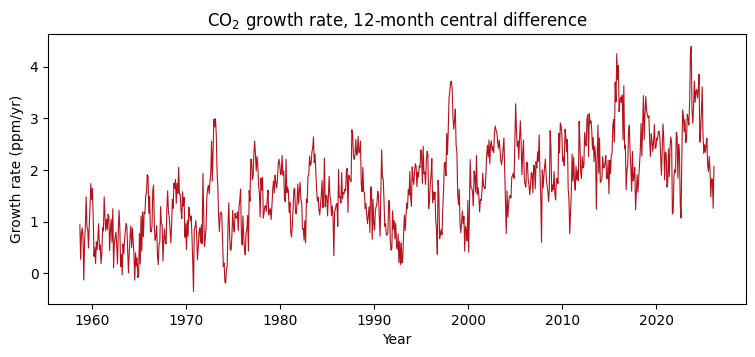

1960s: 0.87 ppm/yr
1970s: 1.26 ppm/yr
1980s: 1.60 ppm/yr
1990s: 1.52 ppm/yr
2000s: 1.99 ppm/yr
2010s: 2.40 ppm/yr
2020s: 2.54 ppm/yr
largest: 4.39 ppm/yr, centred at 2023.7


In [10]:
growth = (y[12:] - y[:-12]) / (t[12:] - t[:-12])
t_mid = (t[12:] + t[:-12]) / 2

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t_mid, growth, lw=0.8, color="#B5121B")
ax.set_xlabel("Year")
ax.set_ylabel("Growth rate (ppm/yr)")
ax.set_title("CO$_2$ growth rate, 12-month central difference")
plt.show()

for decade in range(1960, 2030, 10):
    m = (t_mid >= decade) & (t_mid < decade + 10)
    print(f"{decade}s: {growth[m].mean():.2f} ppm/yr")
print(f"largest: {growth.max():.2f} ppm/yr, centred at {t_mid[np.argmax(growth)]:.1f}")

<span style="color:#38614A">**Answer.**</span> The seasonal cycle has gone and the growth rate is clear: about 0.9 ppm/yr in the 1960s, 1.6 in the 1980s (with a pause in the early 1990s), 2.0 in the 2000s and 2.5 in the 2020s. CO₂ is not just rising; its rise is accelerating, which is why the quadratic model did well in `week3_interpolation.ipynb`. The year-to-year scatter (±1 ppm/yr) is real variability (e.g. El Niño years), plus noise amplified by differencing. The largest values are in 2023–24. Check the file header before reading too much into them: from December 2022 to July 2023 the measurements come from Maunakea, after the Mauna Loa eruption.

In your logbook: why does the 12-month difference remove the seasonal cycle? What would a 6-month difference do?

## <span style="color:#B5121B">3. Differentiating noisy data</span>

With data you can't choose $h$, and the values are not exact. Lecture 4 (Part C) showed what happens: differentiating measured values amplifies their noise. Here is the lecture's example: $x(t) = \cos t$ sampled every $\Delta t$ on $[0, 2\pi)$, each sample with independent noise of standard deviation $\sigma = 0.01$. The exact velocity is $-\sin t$, so you can measure the error.

**(a)** Compute the central-difference velocity at the interior samples, $v_i = (x_{i+1} - x_{i-1})/(2\Delta t)$, using array slicing rather than a loop, and its rms error against $-\sin t$. Compare it with $\sigma/(\sqrt{2}\,\Delta t)$, the noise expected for independent errors. In your logbook: where does the $\sqrt{2}$ come from? How big is the truncation error, at most $\Delta t^2/6$ here, by comparison?

In [11]:
rng = np.random.default_rng(4)
sigma = 0.01

def noisy_cos(dt):
    """Samples of cos(t) on [0, 2 pi) every dt, with independent Gaussian noise of standard deviation sigma."""
    t = np.arange(0, 2 * np.pi, dt)
    return t, np.cos(t) + sigma * rng.standard_normal(len(t))

dt = 0.049
t_n, x_n = noisy_cos(dt)
print(f"{len(t_n)} samples, dt = {dt}")

129 samples, dt = 0.049


In [12]:
def central_velocity(t, x):
    """Central-difference velocity at the interior samples (equal spacing)."""
    dt = t[1] - t[0]
    return (x[2:] - x[:-2]) / (2 * dt)

v = central_velocity(t_n, x_n)
rms = np.sqrt(np.mean((v + np.sin(t_n[1:-1])) ** 2))
print(f"rms error {rms:.3f}; expected from noise sigma/(sqrt2 dt) = {sigma / (np.sqrt(2) * dt):.3f}; "
      f"truncation at most dt^2/6 = {dt**2 / 6:.1e}")

rms error 0.132; expected from noise sigma/(sqrt2 dt) = 0.144; truncation at most dt^2/6 = 4.0e-04


<span style="color:#38614A">**Answer.**</span> The rms error is about 0.13, against 0.14 expected from the noise (the difference is sampling scatter with 127 points), and about 300 times the truncation error ($4\times10^{-4}$). The $\sqrt{2}$: $x_{i+1} - x_{i-1}$ is the difference of two independent errors, so its standard deviation is $\sqrt{2}\,\sigma$; dividing by $2\Delta t$ gives $\sqrt{2}\,\sigma/(2\Delta t) = \sigma/(\sqrt{2}\,\Delta t)$. Each sample is accurate to 1% of the amplitude, but the velocity is only good to about 13%.

**(b)** **Predict first:** if you sample 5 times faster ($\Delta t / 5$), does the velocity get better or worse? Repeat (a) and check against $\sigma/(\sqrt{2}\,\Delta t)$.

In [13]:
t5, x5 = noisy_cos(dt / 5)
v5 = central_velocity(t5, x5)
print(f"dt/5: rms error {np.sqrt(np.mean((v5 + np.sin(t5[1:-1])) ** 2)):.3f}; "
      f"expected {sigma / (np.sqrt(2) * dt / 5):.3f}")

dt/5: rms error 0.722; expected 0.722


<span style="color:#38614A">**Answer.**</span> Worse, by a factor of 5: about 0.72, as expected. The noise term grows as $1/\Delta t$ while the truncation error, already negligible, shrinks. It's the same U-curve as Section 1(b), with measurement noise playing the role of round-off, so the turn-around comes at a much larger step.

**(c)** Lecture 4: *fit locally, then differentiate.* `scipy.signal.savgol_filter(x_n, window, 3, deriv=1, delta=dt)` fits a cubic by least squares to each `window` neighbouring samples and returns its slope. Compute its rms error for windows of 11, 21, 41 and 81 samples, leaving out half a window at each end. Which window is best, and what goes wrong when the window is too wide?

In [14]:
from scipy.signal import savgol_filter

for window in [11, 21, 41, 81]:
    v_s = savgol_filter(x_n, window, 3, deriv=1, delta=dt)
    k = window // 2
    err = np.sqrt(np.mean((v_s[k:-k] + np.sin(t_n[k:-k])) ** 2))
    print(f"window {window:2d} samples ({window * dt:.1f} in t): rms error {err:.4f}")

window 11 samples (0.5 in t): rms error 0.0527
window 21 samples (1.0 in t): rms error 0.0157
window 41 samples (2.0 in t): rms error 0.0059
window 81 samples (4.0 in t): rms error 0.0176


<span style="color:#38614A">**Answer.**</span> The errors fall from about 0.05 (11 samples) to 0.016 (21, the lecture's choice) and 0.006 (41), then rise again to about 0.018 at 81 samples. A wider window averages more noise away, but once it spans a large part of a cycle (81 samples is 4 in $t$, two-thirds of a period) a cubic can no longer follow $\cos t$, and the bias from smoothing the real signal takes over. Keep the window shorter than the fastest real time scale. The ends need care too: within half a window of each end the filter has to extrapolate (Lecture 4, padding), which is why we left those points out.

## <span style="color:#B5121B">4. Numerical integration</span>

Split $[a, b]$ into $n$ intervals of width $h = (b - a)/n$, with points $x_0, \dots, x_n$.

**Trapezoidal rule:** join neighbouring points with straight lines,

$$\int_a^b f\,dx \approx h\left[\tfrac12 f(x_0) + f(x_1) + \dots + f(x_{n-1}) + \tfrac12 f(x_n)\right], \qquad \text{error} \propto h^2.$$

**Simpson's rule** ($n$ even): fit a parabola through each pair of intervals,

$$\int_a^b f\,dx \approx \frac{h}{3}\left[f(x_0) + 4f(x_1) + 2f(x_2) + 4f(x_3) + \dots + 4f(x_{n-1}) + f(x_n)\right], \qquad \text{error} \propto h^4.$$

**(a)** Write `trapezoid(f, a, b, n)` and `simpson(f, a, b, n)`. Use NumPy slicing rather than a loop (`fx[1:-1:2]` picks the odd-indexed points). Raise a `ValueError` in `simpson` if `n` is odd.

In [15]:
def trapezoid(f, a, b, n):
    """Trapezoidal-rule estimate of the integral of f from a to b with n intervals."""
    x = np.linspace(a, b, n + 1)
    fx = f(x)
    h = (b - a) / n
    return h * (0.5 * fx[0] + fx[1:-1].sum() + 0.5 * fx[-1])

def simpson(f, a, b, n):
    """Simpson's-rule estimate of the integral of f from a to b with n (even) intervals."""
    if n % 2:
        raise ValueError("Simpson's rule needs an even number of intervals")
    x = np.linspace(a, b, n + 1)
    fx = f(x)
    h = (b - a) / n
    return h / 3 * (fx[0] + 4 * fx[1:-1:2].sum() + 2 * fx[2:-1:2].sum() + fx[-1])

In [16]:
try:
    print(trapezoid(np.sin, 0, np.pi, 10), simpson(np.sin, 0, np.pi, 10), "exact 2")
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

1.9835235375094546 2.0001095173150043 exact 2


**(b)** **Predict first:** if you double $n$, by what factor should each error fall?

For $\int_0^\pi \sin x\,dx = 2$, compute both errors for $n = 4, 8, 16, \dots, 1024$. Plot error against $h$ on log–log axes and measure the slopes (`np.polyfit` on the logs). Then check your answers against `scipy.integrate.trapezoid`, `scipy.integrate.simpson` and `scipy.integrate.quad`.

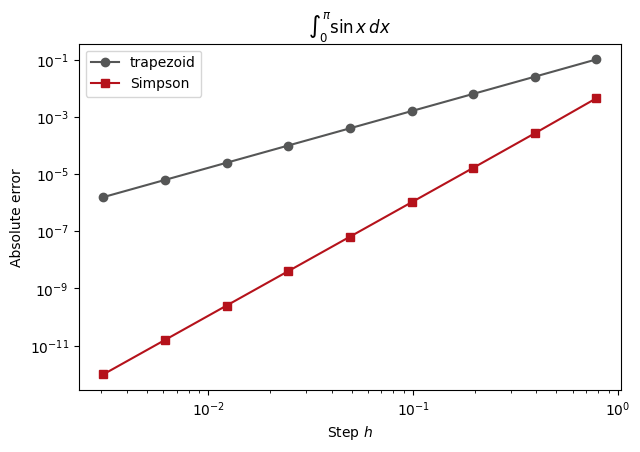

trapezoid slope: 2.00
Simpson slope:   4.01
scipy trapezoid: 1.9998355038874434  mine: 1.9998355038874436
scipy simpson:   2.0000000108245044  mine: 2.000000010824504
scipy quad:      (2.0, 2.220446049250313e-14)


In [17]:
from scipy import integrate

ns = 2 ** np.arange(2, 11)
h = np.pi / ns
err_t = np.array([abs(trapezoid(np.sin, 0, np.pi, n) - 2) for n in ns])
err_s = np.array([abs(simpson(np.sin, 0, np.pi, n) - 2) for n in ns])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(h, err_t, "o-", color="#555656", label="trapezoid")
ax.loglog(h, err_s, "s-", color="#B5121B", label="Simpson")
ax.set_xlabel("Step $h$")
ax.set_ylabel("Absolute error")
ax.set_title(r"$\int_0^\pi \sin x\,dx$")
ax.legend()
plt.show()

ok = err_s > 1e-13          # leave out points at the round-off floor
print(f"trapezoid slope: {np.polyfit(np.log(h), np.log(err_t), 1)[0]:.2f}")
print(f"Simpson slope:   {np.polyfit(np.log(h[ok]), np.log(err_s[ok]), 1)[0]:.2f}")

x = np.linspace(0, np.pi, 101)
print("scipy trapezoid:", integrate.trapezoid(np.sin(x), x), " mine:", trapezoid(np.sin, 0, np.pi, 100))
print("scipy simpson:  ", integrate.simpson(np.sin(x), x=x), " mine:", simpson(np.sin, 0, np.pi, 100))
print("scipy quad:     ", integrate.quad(np.sin, 0, np.pi))

<span style="color:#38614A">**Answer.**</span> Slopes 2.0 (trapezoid) and 4.0 (Simpson): doubling $n$ cuts the trapezoid error by 4 and Simpson's by 16. At $n = 1024$ Simpson is at $10^{-12}$, close to the round-off floor, while the trapezoid is at $10^{-6}$. Both match SciPy to round-off. `quad` returns the value *and* an error estimate; it uses adaptive Gauss–Kronrod quadrature, placing points where the integrand needs them.

## <span style="color:#FD9029">5. Optional: RK4 is Simpson's rule</span>

In Week 1 you wrote RK4 for $dy/dt = f(t, y)$. If $f$ depends only on $t$, solving $dy/dt = f(t)$ from $y(a) = 0$ to $t = b$ *is* computing $\int_a^b f\,dt$.

With $f = f(t)$ only, the RK4 stages are $k_1 = f(t)$, $k_2 = k_3 = f(t + h/2)$, $k_4 = f(t + h)$, so one step is

$$y_{n+1} = y_n + \frac{h}{6}\left[f(t) + 4 f(t + h/2) + f(t + h)\right],$$

which is Simpson's rule on $[t, t + h]$ (with Simpson's spacing $h/2$). Lecture 4 gives the others: Euler becomes the left-rectangle rule and RK2 the midpoint rule, so the orders you measured in Week 1 are the orders of these integration rules.

Check it: integrate $dy/dt = \sin t$ from 0 to π with RK4 using $N$ steps, and compare with `simpson(np.sin, 0, np.pi, 2 * N)`.

In [18]:
def rk4_step(f, t, y, h):
    """One RK4 step for dy/dt = f(t, y): the same stages as your Week 1 RK4 loop."""
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

In [19]:
for N in [2, 5, 10, 50]:
    h = np.pi / N
    y_rk4, t_now = 0.0, 0.0
    for _ in range(N):
        y_rk4 = rk4_step(lambda t, y: np.sin(t), t_now, y_rk4, h)
        t_now += h
    s = simpson(np.sin, 0, np.pi, 2 * N)
    print(f"N = {N:2d}: RK4 = {y_rk4:.15f}, Simpson = {s:.15f}, difference = {abs(y_rk4 - s):.0e}")

N =  2: RK4 = 2.004559754984421, Simpson = 2.004559754984421, difference = 0e+00
N =  5: RK4 = 2.000109517315004, Simpson = 2.000109517315004, difference = 0e+00
N = 10: RK4 = 2.000006784441801, Simpson = 2.000006784441801, difference = 0e+00
N = 50: RK4 = 2.000000010824502, Simpson = 2.000000010824504, difference = 2e-15


<span style="color:#38614A">**Answer.**</span> They agree to round-off ($\sim10^{-16}$) for every $N$. So RK4's fourth-order accuracy in Week 1 and Simpson's $h^4$ error here are the same fact. RK4's extra work (two evaluations at the midpoint, with different $y$) is what extends Simpson's rule to equations where $f$ depends on $y$.

## <span style="color:#B5121B">6. A real integral: the large-amplitude pendulum</span>

The small-angle period of a pendulum is $T_0 = 2\pi\sqrt{L/g}$. At amplitude $\theta_0$ the exact period is

$$\frac{T}{T_0} = \frac{2}{\pi}\int_0^{\pi/2} \frac{d\phi}{\sqrt{1 - k^2 \sin^2\phi}}, \qquad k = \sin(\theta_0/2).$$

The integral is the complete elliptic integral $K$, which SciPy provides as `scipy.special.ellipk(m)` with $m = k^2$ (note: $k^2$, not $k$), so you have an exact answer to check against.

**Predict first:** which rule will be more accurate with $n = 16$, trapezoid or Simpson?

For $\theta_0 = 10°, 90°, 150°, 170°, 179°$, compute $T/T_0$ with both rules ($n = 16$), and print the exact value and both errors.

In [20]:
from scipy.special import ellipk

print("theta0   T/T0 exact   trapezoid err   Simpson err")
for theta0_deg in [10, 90, 150, 170, 179]:
    k = np.sin(np.radians(theta0_deg) / 2)
    integrand = lambda phi: 1 / np.sqrt(1 - k**2 * np.sin(phi) ** 2)
    exact = 2 / np.pi * ellipk(k**2)
    err_t = abs(2 / np.pi * trapezoid(integrand, 0, np.pi / 2, 16) - exact)
    err_s = abs(2 / np.pi * simpson(integrand, 0, np.pi / 2, 16) - exact)
    print(f"{theta0_deg:5d}°   {exact:9.6f}   {err_t:12.1e}   {err_s:11.1e}")

theta0   T/T0 exact   trapezoid err   Simpson err
   10°    1.001907        0.0e+00       0.0e+00
   90°    1.180341        2.2e-16       6.3e-14
  150°    1.762204        1.7e-08       3.8e-05
  170°    2.439363        2.5e-03       1.6e-02
  179°    3.901065        2.0e+00       9.2e-01


<span style="color:#38614A">**Answer.**</span> The trapezoid wins, by a lot: at 150° its error is $2\times10^{-8}$ against Simpson's $4\times10^{-5}$; at 170°, $2.5\times10^{-3}$ against $1.6\times10^{-2}$. (At 10° and 90° both are at round-off.) The $h^2$ and $h^4$ error laws assume nothing special about the integrand. This one is smooth and *periodic*, and the integral runs over a whole number of half-periods, so the trapezoid's error terms from the two ends cancel and it converges faster than any power of $h$. Simpson's unequal 4, 2, 4 weights spoil that cancellation. The "higher-order" rule isn't always better; it depends on the integrand.

At 179° both are poor ($\sim1$): the integrand has a sharp spike at $\phi = \pi/2$ (as $k \to 1$ it diverges), and 16 points can't resolve it. The period also grows without limit as $\theta_0 \to 180°$, the pendulum balanced upside down.

**(b) Optional.** For $\theta_0 = 179°$: how large must $n$ be for the trapezoid to reach $10^{-6}$? What does `scipy.integrate.quad` give, and how many function evaluations does it use (`full_output=1`, then `info["neval"]`)?

In [21]:
from scipy import integrate

k = np.sin(np.radians(179) / 2)
integrand = lambda phi: 1 / np.sqrt(1 - k**2 * np.sin(phi) ** 2)
exact = 2 / np.pi * ellipk(k**2)
for n in [16, 64, 256, 1024, 4096]:
    print(f"trapezoid n = {n:5d}: error = {abs(2 / np.pi * trapezoid(integrand, 0, np.pi / 2, n) - exact):.1e}")
val, err, info = integrate.quad(integrand, 0, np.pi / 2, full_output=1)[:3]
print(f"quad: error = {abs(2 / np.pi * val - exact):.1e} with {info['neval']} evaluations")

trapezoid n =    16: error = 2.0e+00
trapezoid n =    64: error = 1.2e-01
trapezoid n =   256: error = 6.9e-05
trapezoid n =  1024: error = 6.2e-15
trapezoid n =  4096: error = 2.0e-14
quad: error = 1.3e-14 with 273 evaluations


<span style="color:#38614A">**Answer.**</span> The trapezoid reaches $10^{-6}$ between $n = 256$ and $1024$, and round-off by $n = 1024$: once $h$ resolves the spike, the fast convergence for periodic integrands takes over. `quad` reaches round-off with about 270 evaluations, placing them where the integrand needs them. For a hard integrand, adaptive methods are the practical choice; the fixed-grid rules show you *why*.

## <span style="color:#FD9029">7. Optional: why integration gets harder in higher dimensions</span>

On a grid with $n$ points per dimension, a $d$-dimensional integral needs $n^d$ function evaluations. Suppose you can afford $N = 10^6$.

Integrate $f(\mathbf{x}) = e^{-|\mathbf{x}|^2}$ over the cube $[-1, 1]^d$, for which the exact answer is $\left[\sqrt{\pi}\,\text{erf}(1)\right]^d$. The function below applies the trapezoidal rule on a grid with $n$ points per dimension.

**Predict first:** with a fixed budget of $10^6$ evaluations, how does the error change from $d = 1$ to $d = 6$?

For each $d$ from 1 to 6, set $n = \text{round}(N^{1/d})$, compute the relative error and the time taken. Then work out how many evaluations $d = 10$ would need with $n = 10$, and how long that would take at the rate you measured.

In [22]:
from scipy.special import erf

def trapezoid_nd(d, n):
    """Trapezoidal rule for exp(-|x|^2) over [-1, 1]^d with n points per dimension."""
    x = np.linspace(-1, 1, n)
    w = np.full(n, 2 / (n - 1))
    w[[0, -1]] /= 2
    grids = np.meshgrid(*([x] * d), indexing="ij", sparse=True)
    weights = np.meshgrid(*([w] * d), indexing="ij", sparse=True)
    r2 = sum(g**2 for g in grids)
    W = 1.0
    for wk in weights:
        W = W * wk            # broadcasts to the full n^d grid of weights
    return np.sum(W * np.exp(-r2))

exact_1d = np.sqrt(np.pi) * erf(1)

In [23]:
import time
N = 10**6

print(" d    n    points   rel. error    time")
for d in range(1, 7):
    n = int(round(N ** (1 / d)))
    start = time.perf_counter()
    I = trapezoid_nd(d, n)
    elapsed = time.perf_counter() - start
    print(f"{d:2d} {n:6d} {n**d:9d}   {abs(I / exact_1d**d - 1):9.1e}   {elapsed:.3f} s")

rate = n**d / elapsed
print(f"\nd = 10 with n = 10: {10**10:.0e} points, about {10**10 / rate / 60:.0f} minutes at {rate:.0e} points/s,")
print(f"and {10**10 * 8 / 1e9:.0f} GB just to hold the values")

 d    n    points   rel. error    time
 1 1000000   1000000     3.3e-13   0.051 s
 2   1000   1000000     6.6e-07   0.016 s
 3    100   1000000     1.0e-04   0.016 s
 4     32   1048576     1.4e-03   0.015 s
 5     16   1048576     7.3e-03   0.017 s
 6     10   1000000     2.4e-02   0.017 s

d = 10 with n = 10: 1e+10 points, about 3 minutes at 6e+07 points/s,
and 80 GB just to hold the values


<span style="color:#38614A">**Answer.**</span> With the same budget the error grows from $3\times10^{-13}$ ($d = 1$) to $7\times10^{-7}$, $10^{-4}$, $10^{-3}$, $7\times10^{-3}$ and $2\times10^{-2}$ ($d = 6$, only 10 points per side). For error $\propto h^2 \propto n^{-2}$ and $N = n^d$, the error scales as $N^{-2/d}$: each extra dimension makes the same budget buy less accuracy. At $d = 10$ even a coarse 10-point grid is $10^{10}$ evaluations: minutes to hours of computing and 80 GB of memory in this form, for an answer accurate only to a few per cent. Simpson's rule only improves the scaling to $N^{-4/d}$: the same collapse, a few dimensions later. A posterior with 10 parameters is a 10-dimensional integral, so grid quadrature is not an option there.

In your logbook: how does the error scale with $N$ for the trapezoidal rule in $d$ dimensions? Would Simpson's rule ($h^4$) rescue this?

## <span style="color:#FD9029">Extension A (optional): random points instead of a grid</span>

Instead of a grid, evaluate $f$ at $N$ **random** points uniform in $[-1, 1]^d$, and estimate the integral as (volume) × (mean of $f$). Its error falls as $N^{-1/2}$ *whatever the dimension*. Use `np.random.default_rng(1)` and $N = 10^6$ for $d = 1, 3, 6, 10$, and compare the relative errors with Section 7. Where does the random method win? (This is Monte Carlo integration.)

In [24]:
rng = np.random.default_rng(1)
N = 10**6
for d in [1, 3, 6, 10]:
    x = rng.uniform(-1, 1, size=(N, d))
    I = 2.0**d * np.mean(np.exp(-np.sum(x**2, axis=1)))
    print(f"d = {d:2d}: relative error = {abs(I / exact_1d**d - 1):.1e}")

d =  1: relative error = 6.4e-05


d =  3: relative error = 1.7e-04
d =  6: relative error = 5.1e-05


d = 10: relative error = 3.7e-04


<span style="color:#38614A">**Answer.**</span> The random estimate's error is around $10^{-4}$ in every dimension (it varies with the seed; the expected size is the spread of $f$ divided by $\sqrt{N}$). The grid wins clearly for $d \le 2$, they are comparable at $d = 3$, and the random method wins from $d \approx 4$, and at $d = 10$ it is the only one that runs. The grid's error depends on $d$ through $N^{-2/d}$; the random method's doesn't.

## <span style="color:#FD9029">Extension B (optional): how fast does the Lune rise?</span>

Back to the Lancaster Quay tidal record from Weeks 1 and 2 (`lancaster_quay_tidal.csv`, also in this week's `datasets/` folder). Readings are every 15 minutes, with one 30-minute gap.

1. Convert the time to hours since the first reading. Interpolate the level onto a uniform 15-minute grid with `np.interp` (Section 1 of `week3_interpolation.ipynb`, used for real).
2. Compute $dh/dt$ (m/hour) with `np.gradient`, and find the fastest rise and the fastest fall.
3. Lecture 4: *fit locally, then differentiate*. `scipy.signal.savgol_filter(level, window_length, 3, deriv=1, delta=0.25)` fits a cubic to each window of neighbouring points by least squares and returns the slope of that cubic. Try windows of 5, 9, 13 and 17 points (1 to 4 hours). How do the fastest rise and fall change?
4. Plot a day of level and rate together. Does the water rise and fall at the same speed?

sampling intervals (h): [0.25 0.5 ]
central difference:    fastest rise 3.86 m/h, fastest fall -2.01 m/h
local cubic,  5 points: fastest rise 4.29 m/h, fastest fall -2.09 m/h; rising 17% of the time, falling 25%
local cubic,  9 points: fastest rise 3.05 m/h, fastest fall -1.95 m/h; rising 20% of the time, falling 28%
local cubic, 13 points: fastest rise 2.32 m/h, fastest fall -1.89 m/h; rising 23% of the time, falling 32%
local cubic, 17 points: fastest rise 1.88 m/h, fastest fall -1.70 m/h; rising 27% of the time, falling 35%


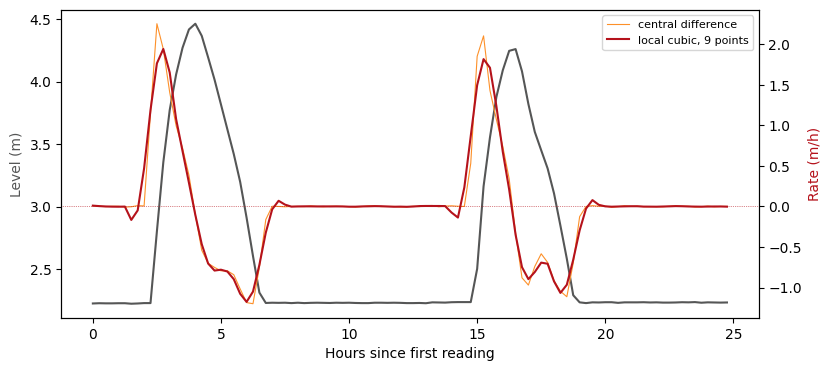

In [25]:
from scipy.signal import savgol_filter

tide = pd.read_csv(data_path("lancaster_quay_tidal.csv"), parse_dates=["time"])
hours = (tide["time"] - tide["time"].iloc[0]).dt.total_seconds().to_numpy() / 3600
print("sampling intervals (h):", np.unique(np.diff(hours)))

t_u = np.arange(0, hours[-1] + 1e-9, 0.25)            # uniform 15-minute grid
level = np.interp(t_u, hours, tide["level_m"].to_numpy())

rate_raw = np.gradient(level, t_u)
print(f"central difference:    fastest rise {rate_raw.max():.2f} m/h, fastest fall {rate_raw.min():.2f} m/h")
for window in [5, 9, 13, 17]:
    rate = savgol_filter(level, window, 3, deriv=1, delta=0.25)
    print(f"local cubic, {window:2d} points: fastest rise {rate.max():.2f} m/h, fastest fall {rate.min():.2f} m/h; "
          f"rising {np.mean(rate > 0.05):.0%} of the time, falling {np.mean(rate < -0.05):.0%}")

rate9 = savgol_filter(level, 9, 3, deriv=1, delta=0.25)
day = t_u < 25
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(t_u[day], level[day], color="#555656")
ax1.set_xlabel("Hours since first reading")
ax1.set_ylabel("Level (m)", color="#555656")
ax2 = ax1.twinx()
ax2.plot(t_u[day], rate_raw[day], color="#FD9029", lw=0.8, label="central difference")
ax2.plot(t_u[day], rate9[day], color="#B5121B", label="local cubic, 9 points")
ax2.axhline(0, color="#B5121B", lw=0.5, ls=":")
ax2.set_ylabel("Rate (m/h)", color="#B5121B")
ax2.legend(fontsize=8, loc="upper right")
plt.show()

<span style="color:#38614A">**Answer.**</span> The central difference gives a fastest rise of 3.9 m/h and fall of 2.0 m/h. With a local cubic the fastest *fall* changes little (2.1 to 1.7 m/h across the windows), but the fastest *rise* drops steadily, from 4.3 to 1.9 m/h, as the window widens. That is the trade-off from Lecture 4: the flood is a real, fast feature lasting about an hour, so a window of several hours smooths the signal, not just the noise. Keep the window shorter than the fastest real time scale: here 5 to 9 points (1–2 hours).

Whatever the window, the asymmetry is clear: the water rises faster than it falls, and spends less time rising (about 20% of the record) than falling (about 28%). The flood comes up the estuary quickly and the ebb drains more slowly: a shape that the M2 + S2 sinusoids of Week 2 can't describe without their higher harmonics.

## Summary

- **Finite differences:** central ($h^2$) beats forward ($h$). The best step balances truncation against round-off, near $\epsilon^{1/3}$ for central differences. Smaller is not always better.
- **Richardson extrapolation** in $h$ removes the leading error when its order is known.
- **Differentiating data** amplifies fast variations and noise: independent errors $\sigma$ give $\sigma/(\sqrt2\,\Delta t)$ in a central difference, so sampling faster makes it worse. Choose the difference, or fit locally first, to suit the signal you want.
- **Quadrature:** trapezoid $h^2$, Simpson $h^4$, but the integrand matters: for smooth periodic integrands the trapezoid can be far better. For hard integrands use an adaptive method (`quad`).
- **RK4 for $dy/dt = f(t)$ is Simpson's rule.**
- **Dimensionality:** grid methods need $n^d$ points, so their accuracy for a fixed budget collapses as $d$ grows.

In your logbook: one result from today that surprised you, and why.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>